# Analisi del dataset McDonald's

Analisi delle percezioni dei consumatori sul brand McDonald's seguendo la **pipeline di data analysis** vista a lezione:

1. **Data collection** – caricamento ed esplorazione dei dati grezzi
2. **Preprocessing** – feature extraction, data cleaning, trasformazione e scaling
3. **Riduzione della dimensionalità** – PCA
4. **Learning non supervisionato** – segmentazione dei clienti con K-means
5. **Learning supervisionato** – predizione del gradimento (`Like`) a partire dalle percezioni
6. **Evaluation** – metriche, matrice di confusione, cross-validation
7. **Prediction** – applicazione del modello finale a nuovi dati

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, accuracy_score,
                             confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline

RANDOM_STATE = 42
FIG = '../figures/'
sns.set_theme(style='whitegrid')

## 1. Data collection ed esplorazione iniziale

In [2]:
df_raw = pd.read_csv('../data/mcdonalds.csv')
print(df_raw.shape)
df_raw.head()

(1453, 15)


,yummy,convenient,spicy,fattening,greasy,fast,cheap,tasty,expensive,healthy,disgusting,Like,Age,VisitFrequency,Gender
0,No,Yes,No,Yes,No,Yes,Yes,No,Yes,No,No,-3,61,Every three months,Female
1,Yes,Yes,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,2,51,Every three months,Female
2,No,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,Yes,No,1,62,Every three months,Female
3,Yes,Yes,No,Yes,Yes,Yes,Yes,Yes,No,No,Yes,4,69,Once a week,Female
4,No,Yes,No,Yes,Yes,Yes,Yes,No,No,Yes,No,2,49,Once a month,Male


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1453 entries, 0 to 1452
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   yummy           1453 non-null   str  
 1   convenient      1453 non-null   str  
 2   spicy           1453 non-null   str  
 3   fattening       1453 non-null   str  
 4   greasy          1453 non-null   str  
 5   fast            1453 non-null   str  
 6   cheap           1453 non-null   str  
 7   tasty           1453 non-null   str  
 8   expensive       1453 non-null   str  
 9   healthy         1453 non-null   str  
 10  disgusting      1453 non-null   str  
 11  Like            1453 non-null   str  
 12  Age             1453 non-null   int64
 13  VisitFrequency  1453 non-null   str  
 14  Gender          1453 non-null   str  
dtypes: int64(1), str(14)
memory usage: 170.4 KB


Il dataset contiene **1453 risposte** a un sondaggio con 15 attributi:

- 11 attributi **binari** (Yes/No) sulla percezione del brand: `yummy`, `convenient`, `spicy`, `fattening`, `greasy`, `fast`, `cheap`, `tasty`, `expensive`, `healthy`, `disgusting`
- `Like`: gradimento su scala da −5 a +5, memorizzato come stringa (gli estremi sono `I hate it!-5` e `I love it!+5`)
- `Age`: numerico
- `VisitFrequency`: categorico **ordinale**
- `Gender`: categorico binario

In [4]:
for c in df_raw.select_dtypes(exclude='number').columns:
    print(f'{c}: {df_raw[c].value_counts().to_dict()}')

yummy: {'Yes': 803, 'No': 650}
convenient: {'Yes': 1319, 'No': 134}
spicy: {'No': 1317, 'Yes': 136}
fattening: {'Yes': 1260, 'No': 193}
greasy: {'Yes': 765, 'No': 688}
fast: {'Yes': 1308, 'No': 145}
cheap: {'Yes': 870, 'No': 583}
tasty: {'Yes': 936, 'No': 517}
expensive: {'No': 933, 'Yes': 520}
healthy: {'No': 1164, 'Yes': 289}
disgusting: {'No': 1100, 'Yes': 353}
Like: {'3': 229, '2': 187, '0': 169, '4': 160, '1': 152, 'I hate it!-5': 152, 'I love it!+5': 143, '-3': 73, '-4': 71, '-2': 59, '-1': 58}
VisitFrequency: {'Once a month': 439, 'Every three months': 342, 'Once a year': 252, 'Once a week': 235, 'Never': 131, 'More than once a week': 54}
Gender: {'Female': 788, 'Male': 665}


## 2. Preprocessing

### 2.1 Data cleaning
Controllo di valori mancanti, duplicati e outlier.

In [5]:
print('Valori mancanti per colonna:')
print(df_raw.isna().sum())
print('\nRighe duplicate:', df_raw.duplicated().sum())

Valori mancanti per colonna:
yummy             0
convenient        0
spicy             0
fattening         0
greasy            0
fast              0
cheap             0
tasty             0
expensive         0
healthy           0
disgusting        0
Like              0
Age               0
VisitFrequency    0
Gender            0
dtype: int64

Righe duplicate: 22


Non ci sono valori mancanti. Ci sono 22 righe duplicate: non essendoci un identificativo del rispondente, potrebbero anche essere persone diverse con risposte identiche, ma su 1453 righe l'impatto è trascurabile e le rimuoviamo come da procedura standard di data cleaning.

In [6]:
df = df_raw.drop_duplicates().reset_index(drop=True)
print(df.shape)

(1431, 15)


Outlier su `Age` (unico attributo numerico continuo) tramite boxplot e regola IQR.

IQR range: [-3.0, 93.0]  ->  outlier: 0


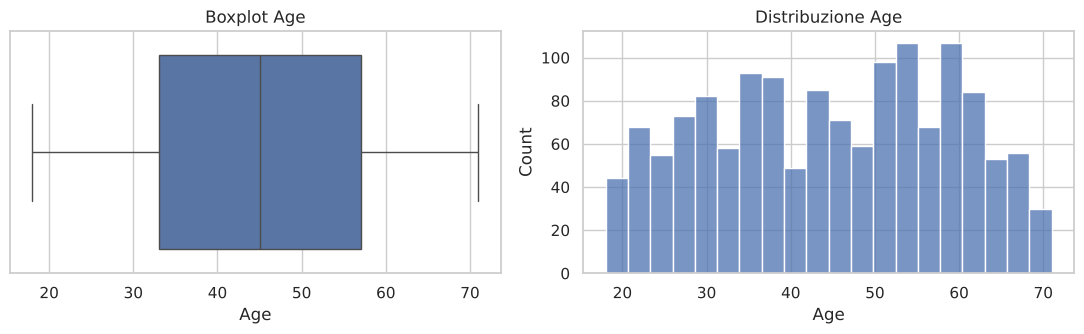

In [7]:
q1, q3 = df['Age'].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f'IQR range: [{low:.1f}, {high:.1f}]  ->  outlier: {((df.Age < low) | (df.Age > high)).sum()}')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
sns.boxplot(x=df['Age'], ax=ax[0]); ax[0].set_title('Boxplot Age')
sns.histplot(df['Age'], bins=20, ax=ax[1]); ax[1].set_title('Distribuzione Age')
plt.tight_layout(); plt.savefig(FIG + 'age_distribution.png', dpi=120); plt.show()

L'età va da 18 a 71 anni, nessun outlier secondo la regola IQR.

### 2.2 Feature extraction (trasformazione in formato numerico)

- attributi binari Yes/No → 1/0
- `Like` → intero da −5 a +5
- `VisitFrequency` → codifica **ordinale** 0–5 (l'ordine ha significato)
- `Gender` → 1 = Female, 0 = Male

In [8]:
binary_cols = ['yummy', 'convenient', 'spicy', 'fattening', 'greasy', 'fast',
               'cheap', 'tasty', 'expensive', 'healthy', 'disgusting']

data = df.copy()
data[binary_cols] = (data[binary_cols] == 'Yes').astype(int)

data['Like'] = (data['Like']
                .replace({'I hate it!-5': '-5', 'I love it!+5': '5'})
                .astype(int))

freq_order = ['Never', 'Once a year', 'Every three months',
              'Once a month', 'Once a week', 'More than once a week']
data['VisitFrequency'] = data['VisitFrequency'].map({v: i for i, v in enumerate(freq_order)})

data['Gender'] = (data['Gender'] == 'Female').astype(int)

data.head()

,yummy,convenient,spicy,fattening,greasy,fast,cheap,tasty,expensive,healthy,disgusting,Like,Age,VisitFrequency,Gender
0,0,1,0,1,0,1,1,0,1,0,0,-3,61,2,1
1,1,1,0,1,1,1,1,1,1,0,0,2,51,2,1
2,0,1,1,1,1,1,0,1,1,1,0,1,62,2,1
3,1,1,0,1,1,1,1,1,0,0,1,4,69,4,1
4,0,1,0,1,1,1,1,0,0,1,0,2,49,3,0


In [9]:
data.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
yummy,1431.0,0.55,0.50,0.0,0.0,1.0,1.0,1.0
convenient,1431.0,0.91,0.29,0.0,1.0,1.0,1.0,1.0
spicy,1431.0,0.10,0.29,0.0,0.0,0.0,0.0,1.0
fattening,1431.0,0.87,0.34,0.0,1.0,1.0,1.0,1.0
greasy,1431.0,0.53,0.50,0.0,0.0,1.0,1.0,1.0
fast,1431.0,0.90,0.30,0.0,1.0,1.0,1.0,1.0
cheap,1431.0,0.60,0.49,0.0,0.0,1.0,1.0,1.0
tasty,1431.0,0.64,0.48,0.0,0.0,1.0,1.0,1.0
expensive,1431.0,0.36,0.48,0.0,0.0,0.0,1.0,1.0
healthy,1431.0,0.20,0.40,0.0,0.0,0.0,0.0,1.0


### 2.3 Analisi esplorativa

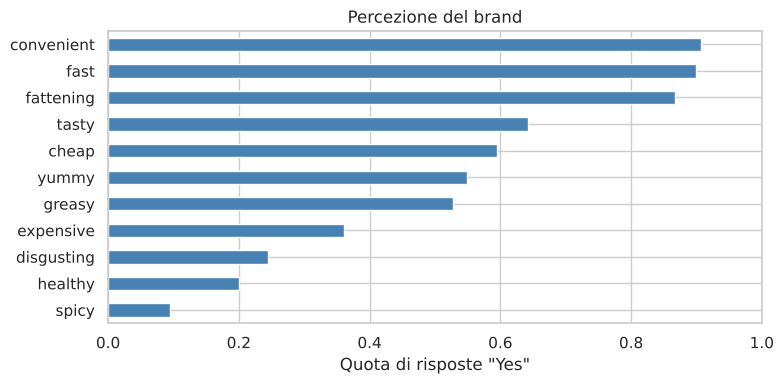

In [10]:
perc = data[binary_cols].mean().sort_values()
plt.figure(figsize=(8, 4))
perc.plot.barh(color='steelblue')
plt.xlabel('Quota di risposte "Yes"'); plt.title('Percezione del brand')
plt.xlim(0, 1); plt.tight_layout(); plt.savefig(FIG + 'perception_bar.png', dpi=120); plt.show()

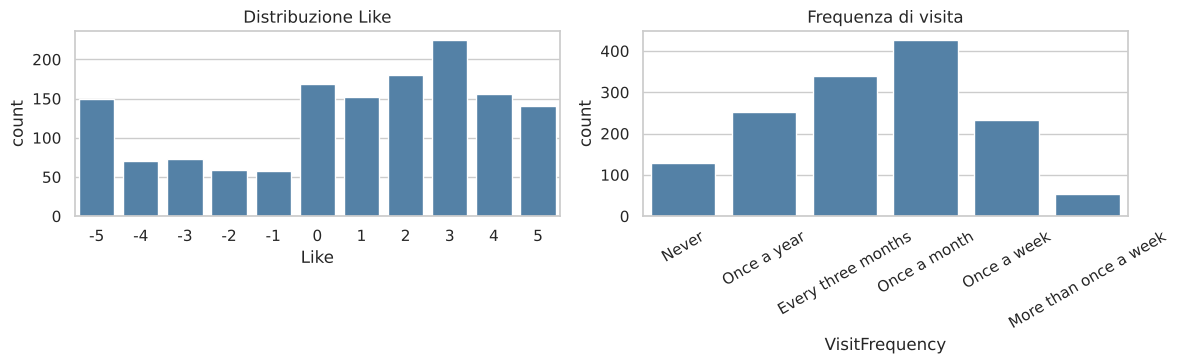

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
sns.countplot(x='Like', data=data, color='steelblue', ax=ax[0]); ax[0].set_title('Distribuzione Like')
sns.countplot(x=df['VisitFrequency'], order=freq_order, color='steelblue', ax=ax[1])
ax[1].set_title('Frequenza di visita'); ax[1].tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.savefig(FIG + 'like_visit.png', dpi=120); plt.show()

Matrice di correlazione: utile anche per individuare attributi ridondanti (data integration / reduction).

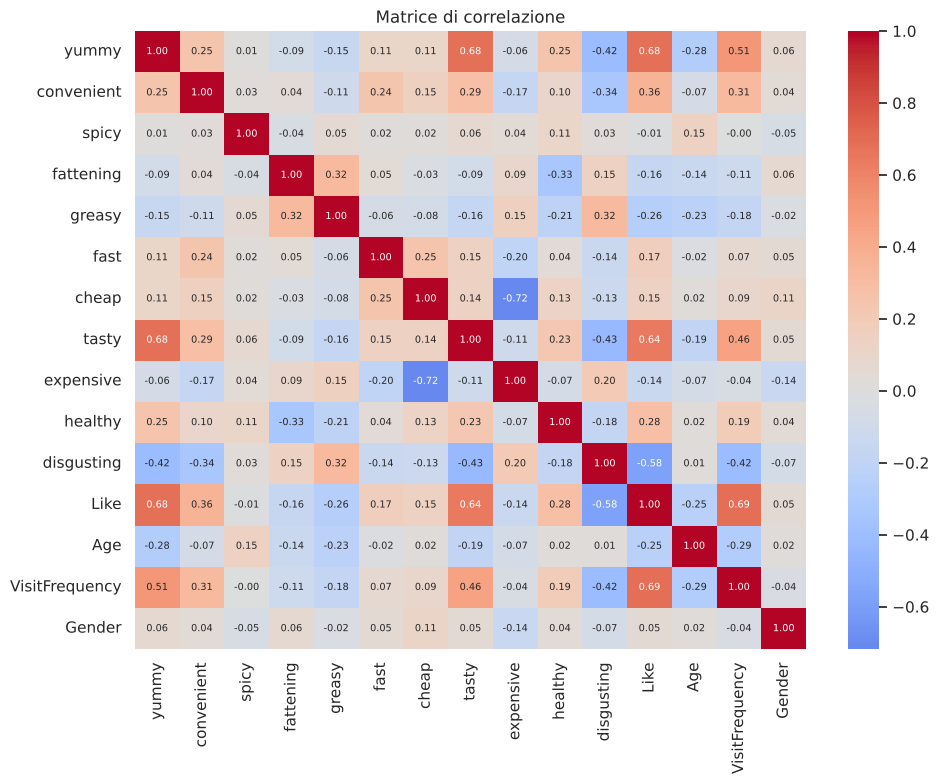

In [12]:
plt.figure(figsize=(10, 8))
sns.heatmap(data.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, annot_kws={'size': 7})
plt.title('Matrice di correlazione'); plt.tight_layout()
plt.savefig(FIG + 'correlation.png', dpi=120); plt.show()

In [13]:
print('Attributi più correlati con Like:')
print(data.corr()['Like'].drop('Like').sort_values(key=abs, ascending=False).round(3))

Attributi più correlati con Like:
VisitFrequency    0.685
yummy             0.680
tasty             0.642
disgusting       -0.578
convenient        0.365
healthy           0.284
greasy           -0.256
Age              -0.247
fast              0.168
fattening        -0.160
cheap             0.146
expensive        -0.140
Gender            0.049
spicy            -0.008
Name: Like, dtype: float64


`VisitFrequency` (0.69), `yummy` (0.68) e `tasty` (0.64) sono gli attributi più correlati con `Like`, mentre `disgusting` è correlato negativamente (−0.58). Tra le percezioni, quelle legate al gusto spiegano il gradimento molto più di quelle su prezzo o salubrità. Attenzione: la frequenza di visita è più una *conseguenza* del gradimento che una sua causa. Nessuna coppia di attributi è così correlata da essere ridondante al punto da eliminarla.

### 2.4 Scaling
Per PCA e K-means le feature devono stare sulla stessa scala: applichiamo la **z-score normalization** (`StandardScaler`) ai soli 11 attributi di percezione, che sono quelli usati per la segmentazione.

In [14]:
X_perc = data[binary_cols].values
X_scaled = StandardScaler().fit_transform(X_perc)
print(X_scaled.mean(axis=0).round(2))
print(X_scaled.std(axis=0).round(2))

[-0. -0.  0. -0. -0.  0. -0. -0. -0.  0.  0.]
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## 3. Riduzione della dimensionalità: PCA

      varianza  cumulata
PC1      0.255     0.255
PC2      0.148     0.403
PC3      0.125     0.528
PC4      0.098     0.626
PC5      0.084     0.710
PC6      0.071     0.781
PC7      0.065     0.846
PC8      0.054     0.900
PC9      0.048     0.948
PC10     0.028     0.976
PC11     0.024     1.000


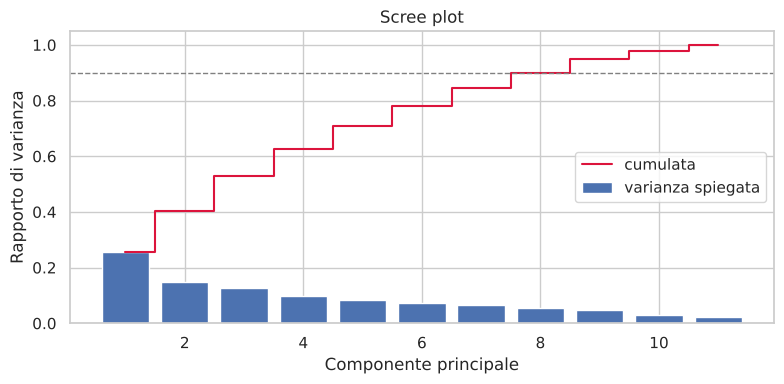

In [15]:
pca = PCA(random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

expl = pca.explained_variance_ratio_
cum = np.cumsum(expl)
print(pd.DataFrame({'varianza': expl.round(3), 'cumulata': cum.round(3)},
                   index=[f'PC{i+1}' for i in range(len(expl))]))

plt.figure(figsize=(8, 4))
plt.bar(range(1, 12), expl, label='varianza spiegata')
plt.step(range(1, 12), cum, where='mid', color='crimson', label='cumulata')
plt.axhline(0.9, ls='--', c='grey', lw=1)
plt.xlabel('Componente principale'); plt.ylabel('Rapporto di varianza')
plt.legend(); plt.title('Scree plot'); plt.tight_layout()
plt.savefig(FIG + 'pca_scree.png', dpi=120); plt.show()

In [16]:
n90 = np.argmax(cum >= 0.90) + 1
print(f'Componenti necessarie per il 90% della varianza: {n90}')

Componenti necessarie per il 90% della varianza: 8


La varianza è distribuita su molte componenti (le prime due spiegano circa il 40%): le percezioni non si comprimono in poche dimensioni. Per la visualizzazione usiamo comunque le prime 2 componenti.

**Loading plot**: quanto ciascun attributo originale contribuisce a PC1 e PC2.

              PC1    PC2
yummy       0.405 -0.287
convenient  0.308  0.047
spicy       0.025 -0.069
fattening  -0.177  0.208
greasy     -0.268  0.133
fast        0.213  0.283
cheap       0.292  0.572
tasty       0.425 -0.245
expensive  -0.294 -0.565
healthy     0.268 -0.204
disgusting -0.409  0.144


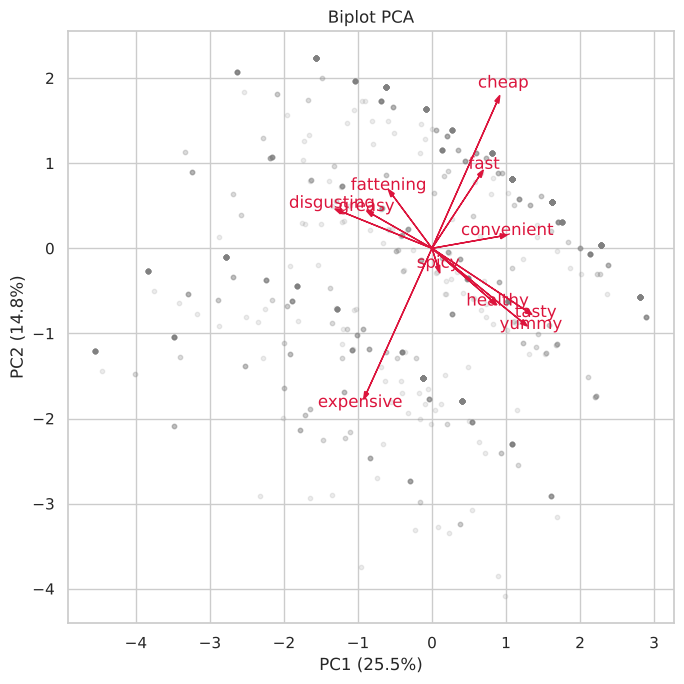

In [17]:
loadings = pd.DataFrame(pca.components_[:2].T, index=binary_cols, columns=['PC1', 'PC2'])
print(loadings.round(3))

plt.figure(figsize=(7, 7))
plt.scatter(X_pca[:, 0], X_pca[:, 1], alpha=0.15, s=10, c='grey')
for name, (x, y) in loadings.iterrows():
    plt.arrow(0, 0, x * 3, y * 3, color='crimson', head_width=0.06)
    plt.text(x * 3.3, y * 3.3, name, color='crimson', ha='center')
plt.xlabel(f'PC1 ({expl[0]:.1%})'); plt.ylabel(f'PC2 ({expl[1]:.1%})')
plt.title('Biplot PCA'); plt.tight_layout()
plt.savefig(FIG + 'pca_biplot.png', dpi=120); plt.show()

- **PC1** separa chi percepisce il prodotto come buono (`yummy`, `tasty`) da chi lo trova `disgusting`/`greasy`: è l'asse del **gusto**.
- **PC2** è dominata da `cheap` contro `expensive`: è l'asse del **prezzo**.

## 4. Learning non supervisionato: segmentazione con K-means

Il numero di cluster K non è noto a priori: lo scegliamo con il **metodo del gomito** (SSE / inerzia) e il **silhouette score**.

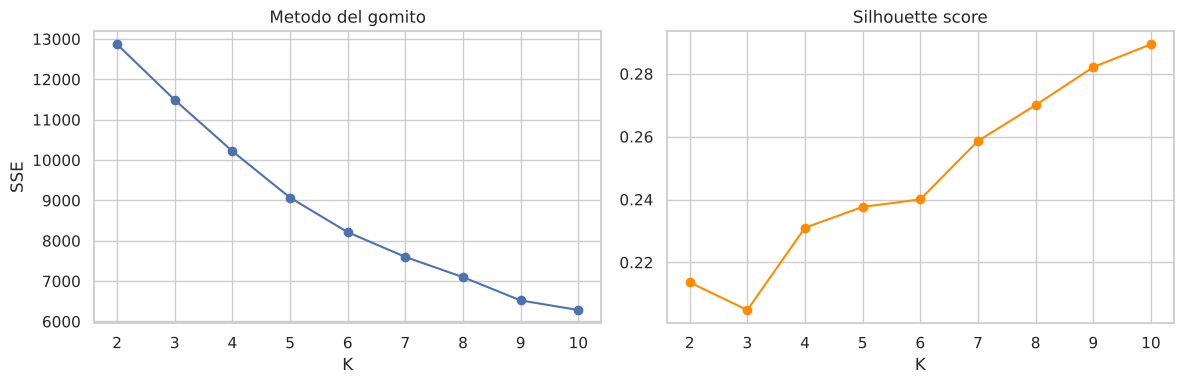

        SSE  silhouette
2   12868.6       0.214
3   11489.4       0.205
4   10219.5       0.231
5    9067.9       0.238
6    8212.5       0.240
7    7599.1       0.259
8    7098.6       0.270
9    6521.3       0.282
10   6283.9       0.289


In [18]:
K = range(2, 11)
sse, sil = [], []
for k in K:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    sse.append(km.inertia_)
    sil.append(silhouette_score(X_scaled, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(K, sse, 'o-'); ax[0].set_title('Metodo del gomito'); ax[0].set_xlabel('K'); ax[0].set_ylabel('SSE')
ax[1].plot(K, sil, 'o-', c='darkorange'); ax[1].set_title('Silhouette score'); ax[1].set_xlabel('K')
plt.tight_layout(); plt.savefig(FIG + 'kmeans_k_selection.png', dpi=120); plt.show()

print(pd.DataFrame({'SSE': np.round(sse, 1), 'silhouette': np.round(sil, 3)}, index=K))

Non c'è un gomito netto e il silhouette è basso per ogni K: con dati binari le percezioni non formano gruppi naturalmente separati, quindi la segmentazione è più una partizione utile che una struttura "vera" dei dati (limite noto di K-means). Scegliamo **K = 4**, un compromesso tra SSE e interpretabilità dei segmenti.

In [19]:
K_BEST = 4
kmeans = KMeans(n_clusters=K_BEST, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
data['Segment'] = kmeans.labels_
print(data['Segment'].value_counts().sort_index())

Segment
0    169
1    727
2    121
3    414
Name: count, dtype: int64


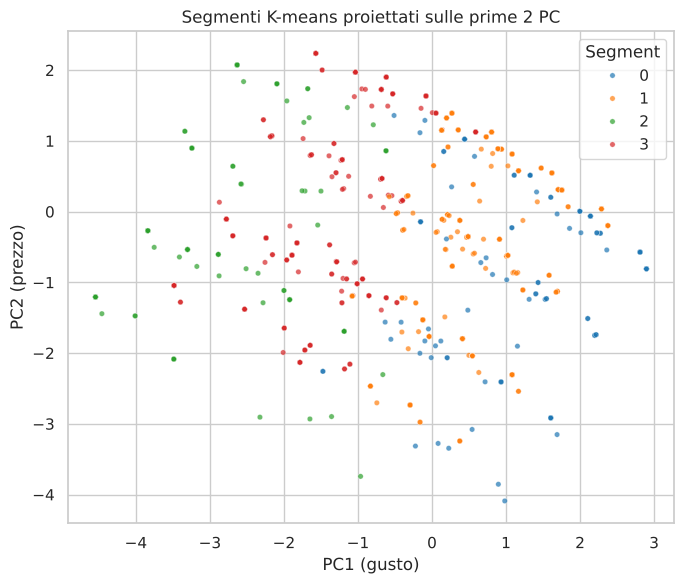

In [20]:
plt.figure(figsize=(7, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=data['Segment'], palette='tab10', s=15, alpha=0.7)
plt.xlabel('PC1 (gusto)'); plt.ylabel('PC2 (prezzo)')
plt.title('Segmenti K-means proiettati sulle prime 2 PC'); plt.tight_layout()
plt.savefig(FIG + 'kmeans_pca.png', dpi=120); plt.show()

### Profilazione dei segmenti
Quota di "Yes" per ogni attributo all'interno di ciascun segmento.

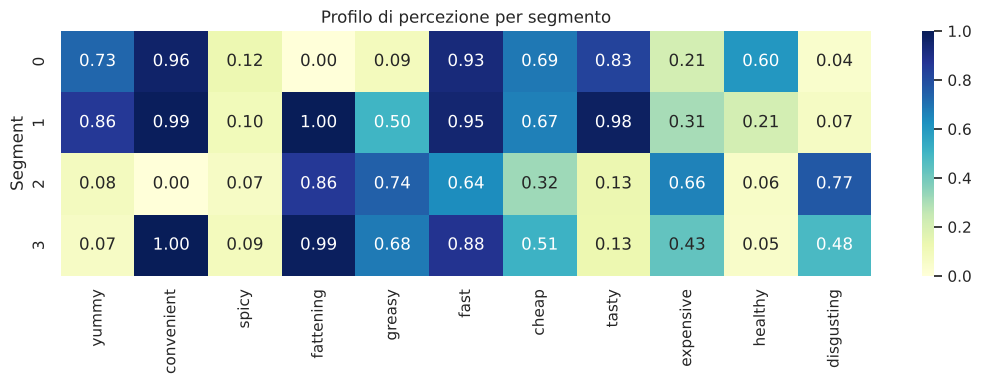

In [21]:
profile = data.groupby('Segment')[binary_cols].mean()
plt.figure(figsize=(11, 4))
sns.heatmap(profile, annot=True, fmt='.2f', cmap='YlGnBu')
plt.title('Profilo di percezione per segmento'); plt.tight_layout()
plt.savefig(FIG + 'segment_profile.png', dpi=120); plt.show()

In [22]:
desc = data.groupby('Segment').agg(
    n=('Like', 'size'),
    Like_medio=('Like', 'mean'),
    Eta_media=('Age', 'mean'),
    Visite_medie=('VisitFrequency', 'mean'),
    Quota_donne=('Gender', 'mean'))
desc.round(2)

,n,Like_medio,Eta_media,Visite_medie,Quota_donne
Segment,,,,,
0,169,2.66,49.70,2.91,0.46
1,727,2.33,41.14,2.85,0.57
2,121,-3.31,47.82,0.99,0.45
3,414,-1.58,47.85,1.75,0.53


| Segmento | Quota | Profilo | Like medio |
|---|---|---|---|
| 0 – *Fan attenti alla salute* | ~12% | buono e gustoso, **non** lo considerano ingrassante, il 60% lo ritiene sano; età media più alta | +2.7 |
| 1 – *Fan consapevoli* | ~51% | gustoso e comodo, ma riconoscono che fa ingrassare; il gruppo più giovane | +2.3 |
| 2 – *Detrattori* | ~8% | non comodo, disgustoso, caro; vengono raramente | −3.3 |
| 3 – *Critici ma utilizzatori* | ~29% | comodo e veloce ma non gustoso, quasi metà lo trova disgustoso | −1.6 |

Il segmento 3 è il più interessante dal punto di vista commerciale: usa il servizio per comodità ma non ne apprezza il gusto.

## 5. Learning supervisionato: predire il gradimento

**Task**: classificare se un cliente **apprezza** McDonald's (`Like > 0`) o no (`Like ≤ 0`) a partire dalle 11 percezioni + età, frequenza di visita e genere.

Seguiamo la pipeline: split train/test → model selection con cross-validation e ottimizzazione degli iperparametri → valutazione sul test set.

In [23]:
feature_cols = binary_cols + ['Age', 'VisitFrequency', 'Gender']
X = data[feature_cols].values
y = (data['Like'] > 0).astype(int).values
print('Distribuzione classi:', np.bincount(y), '->', np.bincount(y) / len(y))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape)

Distribuzione classi: [578 853] -> [0.40391335 0.59608665]
(1144, 14) (287, 14)


Lo split è **stratificato** per mantenere la stessa proporzione delle classi nei due insiemi. Lo scaler è dentro una `Pipeline`, così viene addestrato solo sul training set (niente data leakage).

### Model selection: kNN vs Regressione logistica

kNN      best {'kneighborsclassifier__n_neighbors': 9}  CV acc = 0.847
LogReg   best {'logisticregression__C': 0.01}  CV acc = 0.851


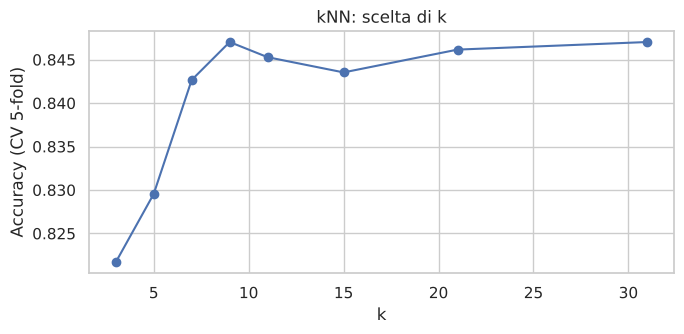

In [24]:
knn_grid = GridSearchCV(
    make_pipeline(StandardScaler(), KNeighborsClassifier()),
    {'kneighborsclassifier__n_neighbors': [3, 5, 7, 9, 11, 15, 21, 31]},
    cv=5, scoring='accuracy').fit(X_train, y_train)

log_grid = GridSearchCV(
    make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    {'logisticregression__C': [0.01, 0.1, 1, 10, 100]},
    cv=5, scoring='accuracy').fit(X_train, y_train)

print(f'kNN      best {knn_grid.best_params_}  CV acc = {knn_grid.best_score_:.3f}')
print(f'LogReg   best {log_grid.best_params_}  CV acc = {log_grid.best_score_:.3f}')

ks = [3, 5, 7, 9, 11, 15, 21, 31]
plt.figure(figsize=(7, 3.5))
plt.plot(ks, knn_grid.cv_results_['mean_test_score'], 'o-')
plt.xlabel('k'); plt.ylabel('Accuracy (CV 5-fold)'); plt.title('kNN: scelta di k')
plt.tight_layout(); plt.savefig(FIG + 'knn_k.png', dpi=120); plt.show()

## 6. Evaluation sul test set

===== kNN =====  accuracy test = 0.836
              precision    recall  f1-score   support

Non apprezza       0.81      0.78      0.79       116
    Apprezza       0.85      0.88      0.86       171

    accuracy                           0.84       287
   macro avg       0.83      0.83      0.83       287
weighted avg       0.84      0.84      0.84       287

===== Logistic Regression =====  accuracy test = 0.850
              precision    recall  f1-score   support

Non apprezza       0.86      0.75      0.80       116
    Apprezza       0.84      0.92      0.88       171

    accuracy                           0.85       287
   macro avg       0.85      0.83      0.84       287
weighted avg       0.85      0.85      0.85       287



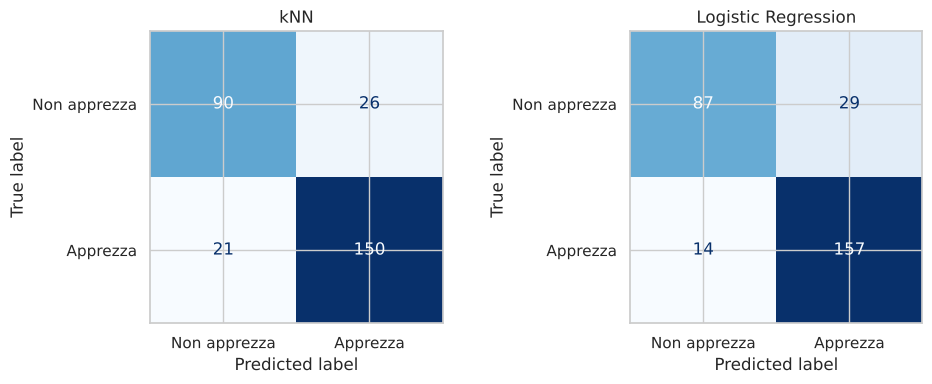

In [25]:
models = {'kNN': knn_grid.best_estimator_, 'Logistic Regression': log_grid.best_estimator_}

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (name, m) in zip(ax, models.items()):
    y_pred = m.predict(X_test)
    print(f'===== {name} =====  accuracy test = {accuracy_score(y_test, y_pred):.3f}')
    print(classification_report(y_test, y_pred, target_names=['Non apprezza', 'Apprezza']))
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                           display_labels=['Non apprezza', 'Apprezza']).plot(ax=a, colorbar=False, cmap='Blues')
    a.set_title(name)
plt.tight_layout(); plt.savefig(FIG + 'confusion_matrices.png', dpi=120); plt.show()

### Interpretazione del modello lineare
I coefficienti della regressione logistica (su feature standardizzate) indicano quali percezioni spingono verso il gradimento.

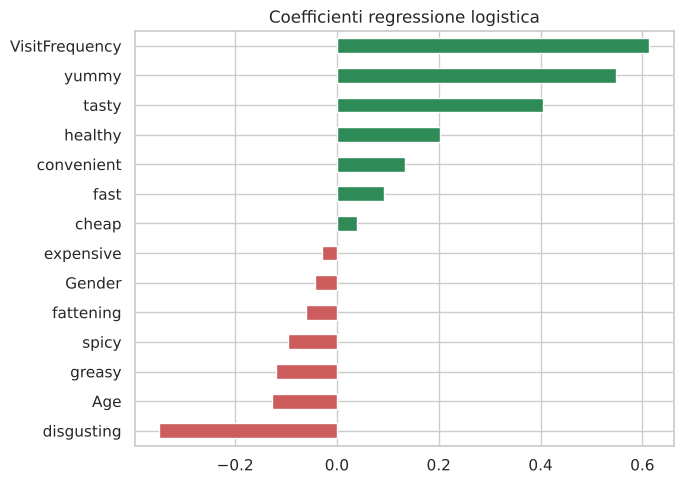

In [26]:
coef = pd.Series(log_grid.best_estimator_[-1].coef_[0], index=feature_cols).sort_values()
plt.figure(figsize=(7, 5))
coef.plot.barh(color=np.where(coef > 0, 'seagreen', 'indianred'))
plt.title('Coefficienti regressione logistica'); plt.tight_layout()
plt.savefig(FIG + 'logreg_coef.png', dpi=120); plt.show()

## 7. Prediction su nuovi dati

Il modello finale (regressione logistica) viene riaddestrato su tutto il dataset e usato su due clienti ipotetici.

In [27]:
final_model = make_pipeline(StandardScaler(),
                            LogisticRegression(C=log_grid.best_params_['logisticregression__C'], max_iter=1000))
final_model.fit(X, y)

new_customers = pd.DataFrame([
    # yummy conv spicy fatt greasy fast cheap tasty exp healthy disg  Age Visit Gender
    [1, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 25, 4, 0],
    [0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 55, 1, 1],
], columns=feature_cols)

proba = final_model.predict_proba(new_customers.values)[:, 1]
for i, p in enumerate(proba):
    print(f'Cliente {i+1}: P(apprezza) = {p:.2f} -> {"Apprezza" if p >= 0.5 else "Non apprezza"}')

Cliente 1: P(apprezza) = 0.94 -> Apprezza
Cliente 2: P(apprezza) = 0.08 -> Non apprezza


## Conclusioni

- I dati erano già completi; il preprocessing è consistito soprattutto nella **conversione in formato numerico** (codifica binaria e ordinale), nella rimozione dei duplicati e nello scaling.
- La **PCA** mostra due assi interpretabili, **gusto** (PC1, 25.5% della varianza) e **prezzo** (PC2, 14.8%), ma servono 8 componenti su 11 per il 90% della varianza.
- **K-means** (K = 4) produce 4 segmenti interpretabili, ma i silhouette bassi (≈ 0.23) indicano che i gruppi non sono nettamente separati.
- Il gradimento è predicibile con circa l'**85% di accuratezza** sul test set (regressione logistica ≈ 0.85, kNN con k = 9 ≈ 0.84); oltre alla frequenza di visita, `yummy`, `tasty` e `disgusting` sono gli attributi più influenti.